# 03 — Augmentação específica de sonar, Vision Transformer, TTA e ensemble

1. **Augmentação física de sonar** (inspirada em BenthicDINO, 2026): ruído *speckle* multiplicativo (Gamma, L ∈ [4,16]), ganho dependente do alcance (gradiente ao longo do eixo across-track) e *random erasing* pequeno — além da augmentação padrão. Só flip **horizontal** (a sombra acústica tem direção física).
2. **MixUp** (α 0,4, p 0,5) sobre a augmentação de sonar.
3. **DeiT-Tiny** (ViT, 5,7 M parâmetros): a literatura (arXiv 2409.12026) reporta ViTs acima de CNNs em sonar.
4. **TTA e ensemble** dos melhores modelos no mesmo holdout (média de probabilidades).

### Protocolo comum (todos os notebooks)
- **Dados:** 1170 imagens side-scan sonar (Marinha Portuguesa, 2010–2021). Rótulo 1 = contém ≥1 **MILCO** (mine-like contact), 255 imagens (21,8%); 0 = só NOMBO ou fundo.
- **Split de triagem (holdout):** estratificado fixo 70/15/15 (seed 42) → treino 819 · validação 175 · teste 176 (38 minas). Mesmo split para todos os experimentos.
- **Seleção do checkpoint:** melhor AUC na **validação** (early stopping). O **threshold** de decisão também é escolhido na validação — o teste só é usado uma vez.
- **Métricas no teste:** ROC-AUC (principal), PR-AUC, F1/precisão/recall com threshold da validação, F1@0.5 e *F1 oráculo* (threshold escolhido no próprio teste, só para comparar com a metodologia do notebook antigo).
- **Atenção:** com 38 positivos no teste, diferenças < ~0,02 de AUC estão dentro do ruído — por isso os finalistas passam por **validação cruzada 5-fold** (notebook 04).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
sys.path.insert(0, str(Path.cwd()))
import sonar_harness as h
import analise as A
fila = json.load(open("fila_experimentos.json"))

In [2]:
# ------------------------------------------------------------------
# (Opcional) Re-treinar os experimentos deste notebook.
# Os resultados abaixo já foram gerados pela fila de execução (máquina local, CPU, treino fatiado).
# Em uma máquina com GPU basta trocar RODAR_TREINO para True: o harness treina de ponta a ponta
# (o mesmo código que roda fatiado também roda sem limite de tempo).
# ------------------------------------------------------------------
RODAR_TREINO = False
GRUPO = "NB03"
jobs = [j for j in fila if j.get("group") == GRUPO]
for j in jobs:
    print(f"{j['id']:45s} {j.get('desc','')}")
if RODAR_TREINO:
    import math
    for j in jobs:
        h.train_job(j, deadline=math.inf)

nb03_effv2b0_sonaraug                         Augmentação específica de sonar (speckle + ganho por alcance + random erasing)
nb03_effv2b0_sonaraug_mixup                   Augmentação de sonar + MixUp (alpha 0.4, p=0.5)
nb03_deittiny_224                             Vision Transformer DeiT-Tiny 224px fine-tuning completo


## Resultados no teste do holdout

In [3]:
runs = {**A.load_runs("nb03_"), **{k: v for k, v in A.load_runs("nb0").items() if k in ("nb01_effv2b0_224_full_adamw", "nb01_baseline_mnv2_96_frozen_adam")}}
df = A.tabela(runs)
df

,experimento,backbone,res,treino,otimizador,loss,aug,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val),F1@0.5,F1 oráculo,épocas,treino (min),inferência (ms/img CPU)
0,nb01_effv2b0_224_full_adamw,tf_efficientnetv2_b0,224,full,adamw,bce,standard,0.957,0.882,0.771,0.844,0.711,0.765,0.818,21,24.502,17.384
1,nb03_deittiny_224,deit_tiny_patch16_224,224,full,adamw,bce,standard,0.942,0.881,0.774,0.655,0.947,0.810,0.833,25,22.518,19.664
2,nb03_effv2b0_sonaraug,tf_efficientnetv2_b0,224,full,adamw,bce,sonar,0.933,0.833,0.767,0.800,0.737,0.762,0.805,22,21.487,18.376
3,nb03_effv2b0_sonaraug_mixup,tf_efficientnetv2_b0,224,full,adamw,bce,sonar+mixup,0.928,0.851,0.773,0.784,0.763,0.775,0.789,25,24.468,19.272
4,nb01_baseline_mnv2_96_frozen_adam,mobilenetv2_100,96,frozen,adam,bce,baseline,0.909,0.805,0.735,0.833,0.658,0.727,0.753,19,0.927,2.333


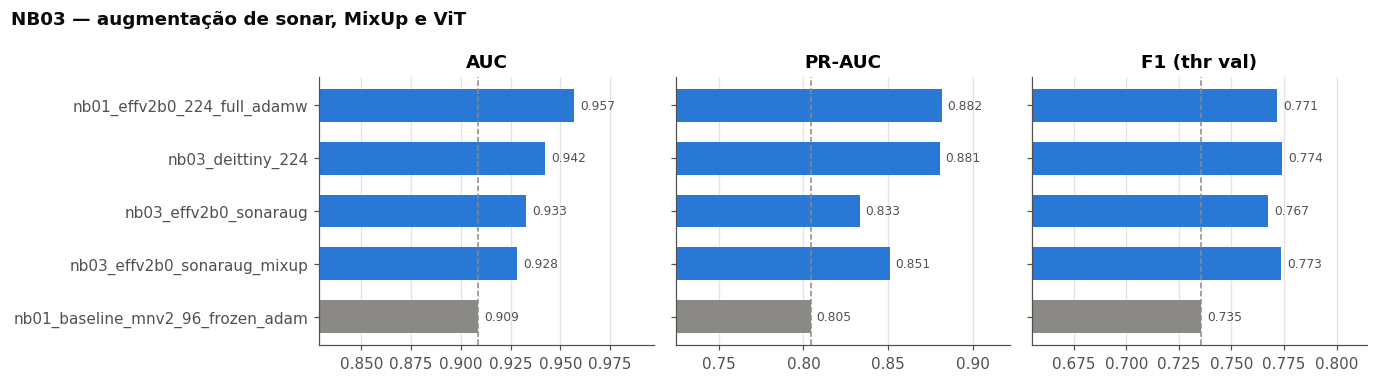

In [4]:
A.barras(df, titulo="NB03 — augmentação de sonar, MixUp e ViT", arquivo="nb03_barras.png");

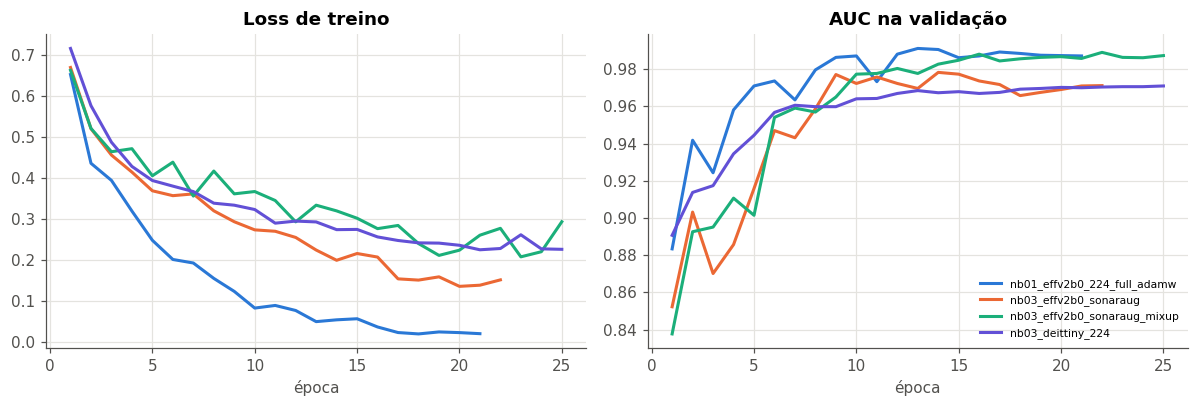

In [5]:
A.curvas_treino(runs, ["nb01_effv2b0_224_full_adamw","nb03_effv2b0_sonaraug","nb03_effv2b0_sonaraug_mixup","nb03_deittiny_224"], arquivo="nb03_curvas.png");

## TTA e ensemble de modelos (holdout)

In [6]:
todos = A.load_runs("nb0")
cands = {
  "SAM EffV2-B0 224": ["nb02_effv2b0_sam_adamw"],
  "ConvNeXt-Pico 320": ["nb01_convnextpico_320_full_adamw"],
  "Ens: SAM EffV2 + ConvNeXt320": ["nb02_effv2b0_sam_adamw","nb01_convnextpico_320_full_adamw"],
  "Ens: SAM EffV2 + ConvNeXt320 + Adam EffV2": ["nb02_effv2b0_sam_adamw","nb01_convnextpico_320_full_adamw","nb02_effv2b0_adam_plateau"],
  "Ens: top-5 por AUC val": sorted(todos, key=lambda k: -todos[k]["best_val_auc"])[:5],
}
rows = []
for nome, ids in cands.items():
    for tta in (False, True):
        m = A.ensemble_holdout(ids, tta=tta)
        rows.append({"modelo": nome, "TTA": tta, "AUC": m["auc"], "PR-AUC": m["pr_auc"], "F1 (thr val)": m["tval_f1"],
                     "Precisão (thr val)": m["tval_precision"], "Recall (thr val)": m["tval_recall"]})
pd.DataFrame(rows)

,modelo,TTA,AUC,PR-AUC,F1 (thr val),Precisão (thr val),Recall (thr val)
0,SAM EffV2-B0 224,False,0.963,0.918,0.841,0.935,0.763
1,SAM EffV2-B0 224,True,0.961,0.906,0.824,0.933,0.737
2,ConvNeXt-Pico 320,False,0.961,0.872,0.843,0.778,0.921
3,ConvNeXt-Pico 320,True,0.964,0.878,0.921,0.921,0.921
4,Ens: SAM EffV2 + ConvNeXt320,False,0.972,0.929,0.860,0.771,0.974
5,Ens: SAM EffV2 + ConvNeXt320,True,0.969,0.907,0.871,0.787,0.974
6,Ens: SAM EffV2 + ConvNeXt320 + Adam EffV2,False,0.969,0.921,0.841,0.740,0.974
7,Ens: SAM EffV2 + ConvNeXt320 + Adam EffV2,True,0.970,0.913,0.886,0.854,0.921
8,Ens: top-5 por AUC val,False,0.955,0.888,0.864,0.814,0.921
9,Ens: top-5 por AUC val,True,0.956,0.879,0.758,0.893,0.658


## Leitura
- A **augmentação física de sonar** (com ou sem MixUp) **piorou** o teste (AUC ≈ 0,93 vs 0,957), apesar de AUC alta na validação: com objetos de poucos pixels, speckle forte e oclusão apagam justamente a assinatura do alvo. Não recomendado sem calibrar a intensidade.
- **DeiT-Tiny** ficou abaixo das CNNs (AUC ≈ 0,94) — com 819 imagens de treino e sem pré-treino em sonar, a vantagem reportada para ViTs não apareceu.
- **TTA** tem efeito pequeno e inconsistente; **ensembles** de modelos diferentes tendem a estabilizar as métricas — confirmado em 5-fold no notebook 04.